In [1]:
from pennylane_functions_3 import loss_function, func_and_deriv, u
from pennylane import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt

/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [5]:
#Set seed:
RANDOM_STATE = 42
seed = np.random.seed(RANDOM_STATE)

epochs = 250
num_qubits = 6
x = np.linspace(0,0.9,20)
l = 5
x0 = 0 
u0 = 1
kappa = 0.1

In [3]:
def training(epochs):
    losses = []
    theta = np.array(2*np.pi*np.random.random(num_qubits*l*3), requires_grad=True)
    for i in range(epochs):
        print("epoch number = ", i)
        loss = loss_function(x,num_qubits,theta, l, i, epochs)
        print("Current loss:", loss)
        losses.append(loss)
        optimizer = qml.AdamOptimizer()
        theta = optimizer.step(lambda theta: loss_function(x,num_qubits,theta, l, i, epochs), theta)
        print("Finished optimizing.")
        print()

    return theta, losses

epoch number =  0
Current loss: 897.4648549618562
Finished optimizing.

epoch number =  1
Current loss: 637.5362557311166
Finished optimizing.

epoch number =  2
Current loss: 501.9499285205332
Finished optimizing.

epoch number =  3
Current loss: 397.86730289130287
Finished optimizing.

epoch number =  4
Current loss: 359.2316589836199
Finished optimizing.

epoch number =  5
Current loss: 324.00498201406174
Finished optimizing.

epoch number =  6
Current loss: 328.42313765720195
Finished optimizing.

epoch number =  7
Current loss: 289.9495336806748
Finished optimizing.

epoch number =  8
Current loss: 300.9073765950374
Finished optimizing.

epoch number =  9
Current loss: 258.5984298471695
Finished optimizing.

epoch number =  10
Current loss: 269.0499471955628
Finished optimizing.

epoch number =  11
Current loss: 239.3107229142011
Finished optimizing.

epoch number =  12
Current loss: 258.38793709271386
Finished optimizing.

epoch number =  13
Current loss: 218.45579602397893
Finis

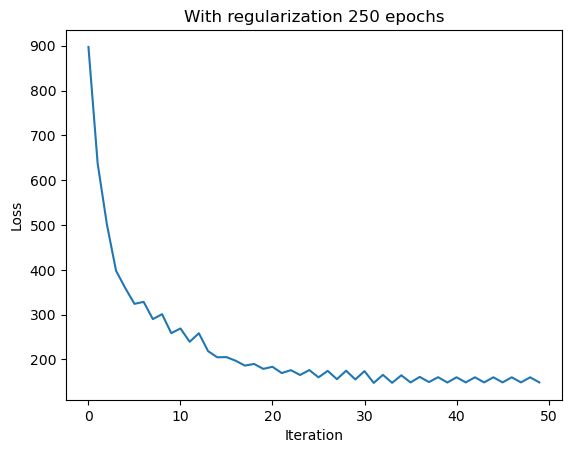

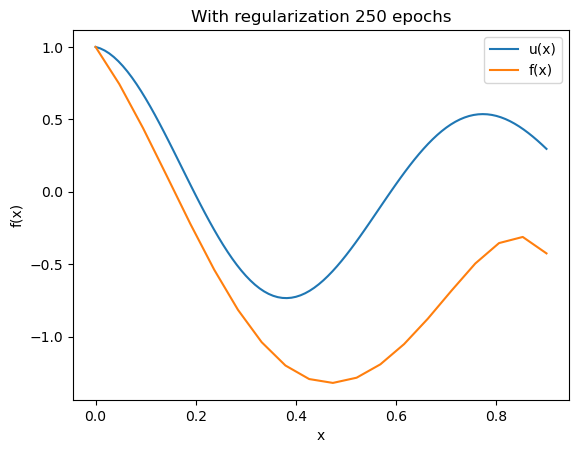

In [4]:
theta_opt, losses = training(epochs)

#Plot the results
plt.plot(losses)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("With regularization 250 epochs")
plt.savefig("losses_without_regularization_cheb.png")
plt.show()

f, df = func_and_deriv(x, num_qubits, theta_opt, l)

x2 = np.linspace(0,0.9,100)
u_plot = u(x2, x0, u0, kappa)

plt.plot(x2, u_plot, label="u(x)")
plt.plot(x, f*2-1, label="f(x)")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.title("With regularization 250 epochs")
plt.savefig("f_x_without_regularization_cheb.png")
plt.show()